<a href="https://colab.research.google.com/github/MariaMinottaZ/movie-review-sentiment-analysis/blob/main/LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook there will be trained and tested a LSTM with embeddings

# Import dataset

In [1]:
import kagglehub

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Path to dataset files: /kaggle/input/imdb-dataset-of-50k-movie-reviews


Extract content

In [2]:
import pandas as pd
import os

csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print(csv_files)

['/kaggle/input/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv']


In [3]:
columns = [
    "review",
    "sentiment"
]

df = pd.read_csv(
    csv_files[0],
    encoding="ISO-8859-1",
    header=None,
    names=columns
)

 # Preprocessing

Delete outlier

In [4]:
df = df[df["sentiment"] != "sentiment"].copy()

Clean text

In [5]:
import re

def clean_text(text):

    text = text.lower()

    text = re.sub(r"<br\s*/?>", " ", text)

    text = re.sub(r"http\S+|www\.\S+", "", text)

    text = re.sub(r"https\S+|www\.\S+", "", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

Applied to reviews

In [6]:
df["clean_text"] = df["review"].apply(clean_text)

# Creating model

## Import model and training

In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

X = df["clean_text"].astype(str)
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
y_train = y_train.map({
    "negative": 0,
    "positive": 1
})

y_test = y_test.map({
    "negative": 0,
    "positive": 1
})

In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 20000
max_len = 200

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print(X_train_pad.shape)

(40000, 200)


Import and train model

In [10]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


model_lstm = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=100,
        mask_zero=True
    ),

    LSTM(
        64,
        dropout=0.2
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        1,
        activation="sigmoid"
    )
])

model_lstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_lstm.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_lstm = model_lstm.fit(
    X_train_pad,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 157s 309ms/step - accuracy: 0.7810 - loss: 0.4625 - val_accuracy: 0.8635 - val_loss: 0.3419
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 286ms/step - accuracy: 0.8967 - loss: 0.2698 - val_accuracy: 0.8580 - val_loss: 0.3307
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 206s 294ms/step - accuracy: 0.9323 - loss: 0.1858 - val_accuracy: 0.8751 - val_loss: 0.3524
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 141s 282ms/step - accuracy: 0.9526 - loss: 0.1310 - val_accuracy: 0.8646 - val_loss: 0.4964
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 142s 280ms/step - accuracy: 0.9677 - loss: 0.0956 - val_accuracy: 0.8669 - val_loss: 0.4700


Metrics

In [12]:
test_loss, test_accuracy = model_lstm.evaluate(
    X_test_pad,
    y_test
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.8593 - loss: 0.3373
Test loss: 0.33733367919921875
Test accuracy: 0.8593000173568726


## Metrics

Confusion matrix

In [13]:
y_prob_lstm = model_lstm.predict(X_test_pad)

y_pred_lstm = (y_prob_lstm >= 0.5).astype(int).flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step


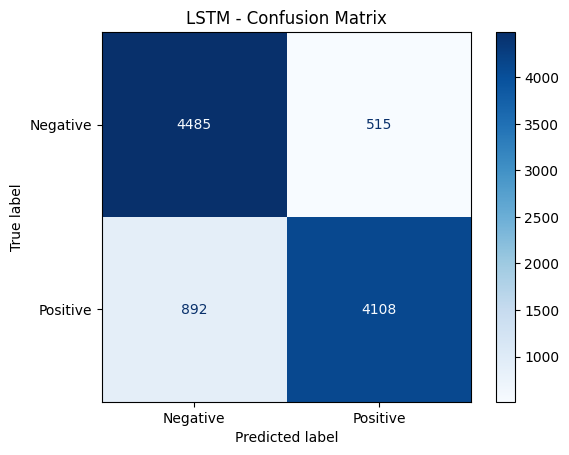

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lstm = confusion_matrix(y_test, y_pred_lstm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lstm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LSTM - Confusion Matrix")
plt.show()

Other metrics

In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.83      0.90      0.86      5000
    Positive       0.89      0.82      0.85      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



# Testing model

Real reviews:

-"The new hunger games movie is absolutely beautiful. The sets, designs, outfits, environment. Its all so gorgeous. The acting is also really engaging. The comedy mostly comes from the character acting. It was very fun. Ceasar, I love you. The thing that makes this movie meh is the pacing. Every bit and moment goes by so fast yet it still expects you to take it seriously. Character comes in, character dies. Over and over. Its REALLY bad, the pacing. It makes it really difficult to connect with the characters and/or events, just like how the book did. To be fair, the book is like 4 hours of story telling, so this movie HAD to compress it, but that comes with a cost. I definently prefer the book."

7/10

-"Before watching The Odyssey, I'd seen loads of mixed reviews, so I went in with an open mind and honestly wasn't expecting much. I couldn't have been more wrong. I was hooked from start to finish. It's one of those films that completely pulls you in, and I enjoyed every minute of it. The performances were outstanding across the board. With a cast like this, you'd expect quality, but everyone played their part brilliantly and really brought the story to life. What I appreciated most was how immersive it felt. For a film that's nearly three hours long, I never found myself checking my phone or thinking about anything else. It was gripping from start to finish. Everyone's entitled to their own opinion, but I absolutely loved this film and would recommend it to anyone."

10/10

-"The most entertaining part of this entire movie was reading these hilariously bad reviews. It was SO boring and hard to watch."

2/10

-"This left me speechless......and not in a breath-taking "Shawshank Redemption" type way! I literally wanted to rip my arm off and throw it at the TV it was so bad. My husband and I made a bet with one another as to who could keep watching it the longest........the loser buying the weekend beers! I was quite happy to lose that night. I had no idea what was going on, it kept skipping from one sketch to another with no plot, no reason and NO POINT! Awful acting, awful impressions, awful film! Pretty much is what it says on the tin, A Disaster. Do not watch this movie. You'd be better off stapling your genitals to a table for an hour...it'll be less painful for you!"

1/10


In [16]:
test_reviews = [
    "The new hunger games movie is absolutely beautiful. The sets, designs, outfits, environment. Its all so gorgeous. The acting is also really engaging. The comedy mostly comes from the character acting. It was very fun. Ceasar, I love you. The thing that makes this movie meh is the pacing. Every bit and moment goes by so fast yet it still expects you to take it seriously. Character comes in, character dies. Over and over. Its REALLY bad, the pacing. It makes it really difficult to connect with the characters and/or events, just like how the book did. To be fair, the book is like 4 hours of story telling, so this movie HAD to compress it, but that comes with a cost. I definently prefer the book.",
    "Before watching The Odyssey, I'd seen loads of mixed reviews, so I went in with an open mind and honestly wasn't expecting much. I couldn't have been more wrong. I was hooked from start to finish. It's one of those films that completely pulls you in, and I enjoyed every minute of it. The performances were outstanding across the board. With a cast like this, you'd expect quality, but everyone played their part brilliantly and really brought the story to life. What I appreciated most was how immersive it felt. For a film that's nearly three hours long, I never found myself checking my phone or thinking about anything else. It was gripping from start to finish. Everyone is entitled to their own opinion, but I absolutely loved this film and would recommend it to anyone.",
    "The most entertaining part of this entire movie was reading these hilariously bad reviews. It was SO boring and hard to watch.",
    "This left me speechless......and not in a breath-taking Shawshank Redemption type way! I literally wanted to rip my arm off and throw it at the TV it was so bad. My husband and I made a bet with one another as to who could keep watching it the longest........the loser buying the weekend beers! I was quite happy to lose that night. I had no idea what was going on, it kept skipping from one sketch to another with no plot, no reason and NO POINT! Awful acting, awful impressions, awful film! Pretty much is what it says on the tin, A Disaster. Do not watch this movie."
]

In [17]:
test_sequences = tokenizer.texts_to_sequences(test_reviews)

test_padded = pad_sequences(
    test_sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

In [18]:
predictions = model_lstm.predict(test_padded)

for review, probability in zip(test_reviews, predictions.flatten()):

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Probability:", round(float(probability), 4))
    print("-" * 60)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Review: The new hunger games movie is absolutely beautiful. The sets, designs, outfits, environment. Its all so gorgeous. The acting is also really engaging. The comedy mostly comes from the character acting. It was very fun. Ceasar, I love you. The thing that makes this movie meh is the pacing. Every bit and moment goes by so fast yet it still expects you to take it seriously. Character comes in, character dies. Over and over. Its REALLY bad, the pacing. It makes it really difficult to connect with the characters and/or events, just like how the book did. To be fair, the book is like 4 hours of story telling, so this movie HAD to compress it, but that comes with a cost. I definently prefer the book.
Sentiment: Negative
Probability: 0.3244
------------------------------------------------------------
Review: Before watching The Odyssey, I'd seen loads of mixed reviews, so I went in with an open mind and honestly wasn't expecting much. I couldn't hav

# Save

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Model

In [20]:
model_lstm.save(
    '/content/drive/MyDrive/Sentiment_Analysis/models/lstm.keras'
)

##Tokenizer

In [21]:
import pickle

with open('/content/drive/MyDrive/Sentiment_Analysis/models/tokenizer_lstm.pkl', 'wb') as file:
    pickle.dump(tokenizer, file)